In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/data.yaml
/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val/Car/Car (568).jpeg
/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val/Car/Car (1442).jpeg
/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val/Car/Car (1331).jpeg
/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val/Car/Car (2).jpg
/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val/Car/Car (338).jpeg
/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val/Car/Car (1789).jpeg
/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val/Car/Car (840).jpeg
/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val/Car/Ca

# Car vs Bike Image Classification Using CNN


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Dense,Flatten,Conv2D,MaxPooling2D,Input,Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.metrics import Recall
from PIL import Image
import os
import cv2
import random
import json
import seaborn as sns
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix,classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
import warnings
warnings.filterwarnings('ignore')

# Dataset Paths

In [3]:
base_dir = '/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset'
train_dir = '/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/train'
test_dir = '/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/test'
val_dir = '/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val'

# Explore Class Names

In [4]:
class_names = os.listdir(train_dir)

In [5]:
class_names

['Car', 'Bike']

# Encode Class Labels

In [6]:
class_to_index = {name: i for i,name in enumerate(class_names)}

In [7]:
class_to_index

{'Car': 0, 'Bike': 1}

# Load and Preprocess Images

In [8]:
def load_data(data_dir , image_size=(224,224)):
    images = []
    labels= []
    for label_name in os.listdir(data_dir):
        label_path = os.path.join(data_dir , label_name)
        if not os.path.isdir(label_path):
            continue
        for img_file in os.listdir(label_path):
            img_path = os.path.join(label_path , img_file)
            img = cv2.imread(img_path)
            if img is None:
                continue 
            img = cv2.cvtColor(img , cv2.COLOR_BGR2RGB)
            img = cv2.resize(img , image_size)
            images.append(img)
            labels.append(class_to_index[label_name])

    images = np.array(images)/255.0
    labels = np.array(labels)
    return images , labels

In [9]:
train_img , train_label = load_data(train_dir)
test_img , test_label = load_data(test_dir)
val_img , val_label = load_data(val_dir)

In [10]:
print('Train: ' , train_img.shape , train_label.shape)
print('Validation: ' , val_img.shape , val_label.shape)
print('Test: ' , test_img.shape , test_label.shape)

Train:  (2800, 224, 224, 3) (2800,)
Validation:  (600, 224, 224, 3) (600,)
Test:  (600, 224, 224, 3) (600,)


In [11]:
train_img[0]

array([[[0.42352941, 0.50196078, 0.99215686],
        [0.43137255, 0.50980392, 0.98823529],
        [0.44313725, 0.5254902 , 0.98823529],
        ...,
        [0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157]],

       [[0.42745098, 0.50980392, 0.98431373],
        [0.43529412, 0.51764706, 0.98039216],
        [0.45098039, 0.53333333, 0.98039216],
        ...,
        [0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157]],

       [[0.43921569, 0.52156863, 0.96470588],
        [0.44705882, 0.52941176, 0.96470588],
        [0.45882353, 0.54901961, 0.96470588],
        ...,
        [0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157]],

       ...,

       [[0.6627451 , 0.6627451 , 0.63137255],
        [0.66666667, 0.66666667, 0.63529412],
        [0.66666667, 0

# Explore Class Distribution

In [12]:
_,count = np.unique(train_label , return_counts=True)

<Axes: >

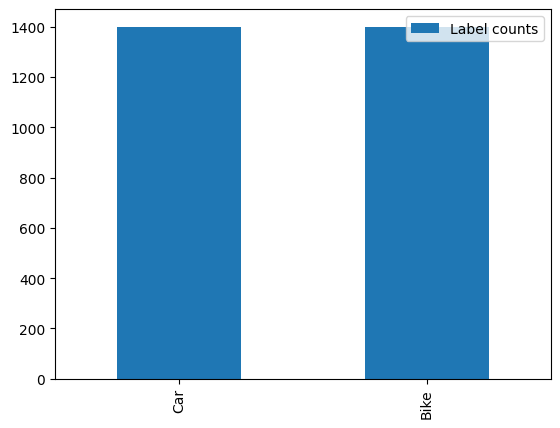

In [13]:
pd.DataFrame({'Label counts' : count} , index=class_to_index).plot.bar()

# Create Reverse Label Mapping

In [14]:
index_to_class = {v:k for k,v in class_to_index.items()}

# Define Image Visualization Function

In [15]:
def display_images(images , labels , n=10):
    plt.figure(figsize=(15,6))
    for i in range(n):
        idx = random.randint(0 , len(images)-1)

        plt.subplot(2, 5 , i+1)
        plt.imshow(images[idx])
        plt.title(f"Label: {index_to_class[labels[idx]]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

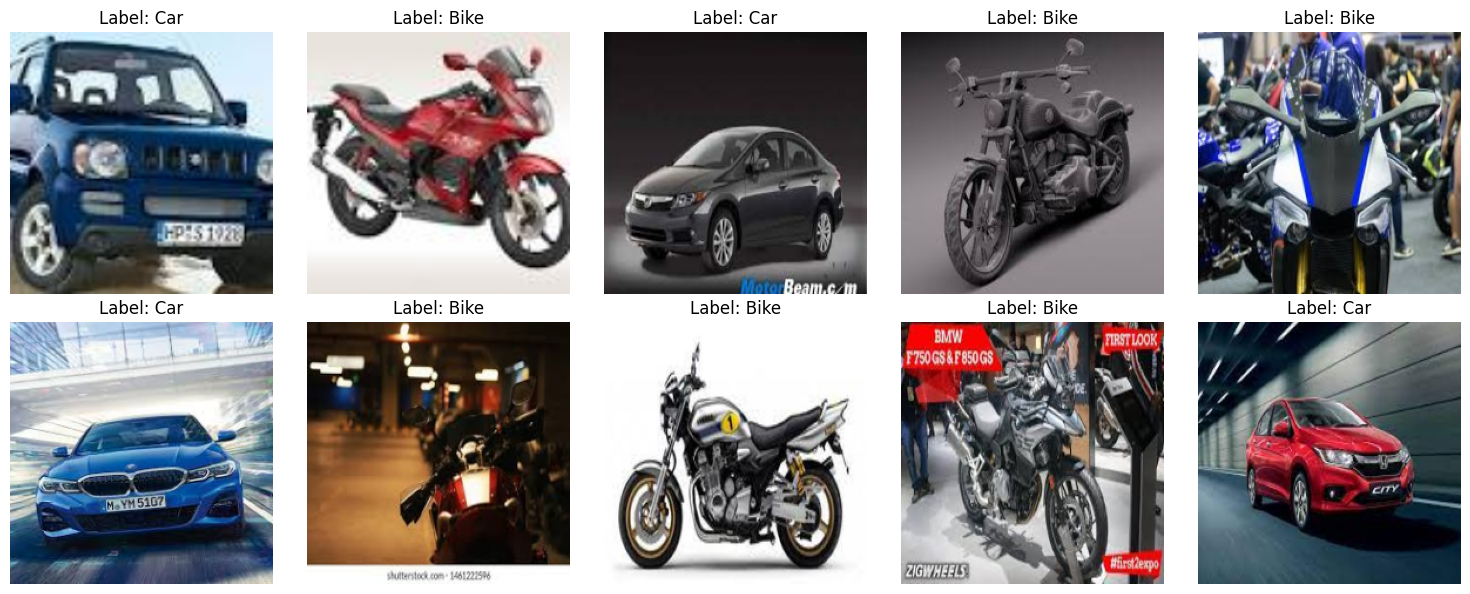

In [16]:
display_images(train_img , train_label , 10)

In [17]:
train_label

array([0, 0, 0, ..., 1, 1, 1])

# Shuffle Training Data

In [18]:
indices = np.arange(len(train_img))
np.random.shuffle(indices)
train_img = train_img[indices]
train_label = train_label[indices]

In [19]:
train_label

array([0, 1, 1, ..., 1, 0, 0])

# Data Augmentation

In [20]:
datagen = ImageDataGenerator(
    rotation_range = 15 ,
    width_shift_range = 0.2,
    height_shift_range = 0.1,
    zoom_range = 0.1
)

In [21]:
train_generator = datagen.flow(
    train_img ,
    train_label,
    batch_size = 32,
    shuffle=True
)

# Build the CNN Model

In [22]:
CNN = Sequential([
    Input(shape=(224, 224, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])


I0000 00:00:1791672456.016381      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791672456.020101      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [23]:
CNN.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
CNN.compile(
    optimizer='adam',
    loss = 'binary_crossentropy',
    metrics=['accuracy']
)

In [25]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

# Train the Model

In [26]:
history = CNN.fit(
    train_generator,
    steps_per_epoch = len(train_img)//32,
    validation_data = (val_img , val_label),
    epochs=25,
    callbacks=[early_stop]
)

Epoch 1/25


2026-10-10 22:47:43.752166: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-10 22:47:43.899941: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 1/87 ━━━━━━━━━━━━━━━━━━━━ 11:39 8s/step - accuracy: 0.5000 - loss: 0.6989

I0000 00:00:1791672466.669470     175 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-10-10 22:47:48.189070: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-10 22:47:48.333907: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


87/87 ━━━━━━━━━━━━━━━━━━━━ 41s 384ms/step - accuracy: 0.5878 - loss: 0.7044 - val_accuracy: 0.8017 - val_loss: 0.4637
Epoch 2/25
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7500 - loss: 0.5764 - val_accuracy: 0.8183 - val_loss: 0.4466
Epoch 3/25
87/87 ━━━━━━━━━━━━━━━━━━━━ 27s 312ms/step - accuracy: 0.8111 - loss: 0.4333 - val_accuracy: 0.8900 - val_loss: 0.2809
Epoch 4/25
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.2333 - val_accuracy: 0.8917 - val_loss: 0.2698
Epoch 5/25
87/87 ━━━━━━━━━━━━━━━━━━━━ 27s 309ms/step - accuracy: 0.8524 - loss: 0.3433 - val_accuracy: 0.9083 - val_loss: 0.2339
Epoch 6/25
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8750 - loss: 0.2117 - val_accuracy: 0.9083 - val_loss: 0.2275
Epoch 7/25
87/87 ━━━━━━━━━━━━━━━━━━━━ 27s 307ms/step - accuracy: 0.8783 - loss: 0.2972 - val_accuracy: 0.9133 - val_loss: 0.2460
Epoch 8/25
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8438 - loss: 0.4797 - val_accuracy: 0.9217 - val_loss

# Visualize Training Performance

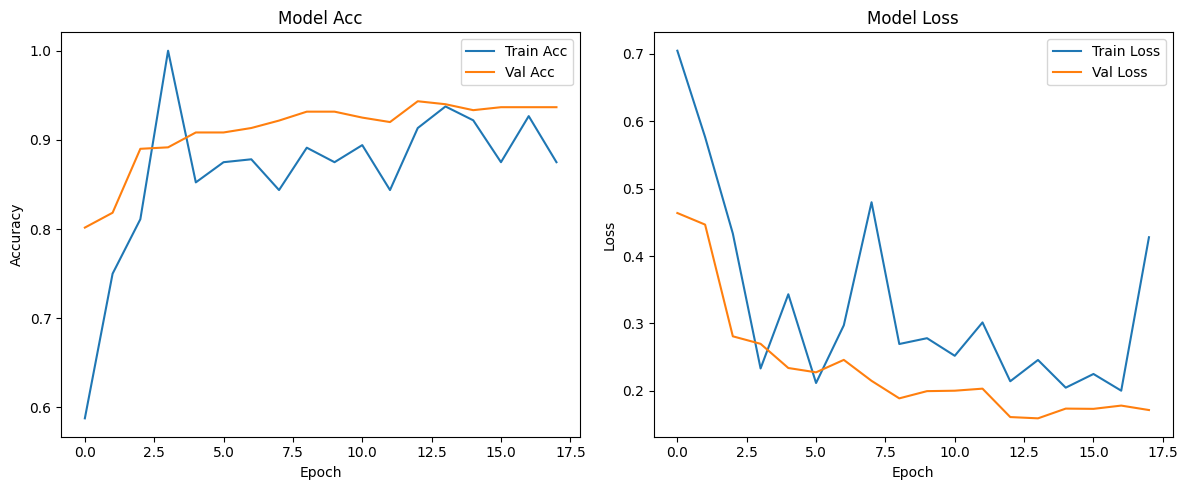

In [27]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Model Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [28]:
test_loss, test_acc = CNN.evaluate(test_img, test_label)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9450 - loss: 0.1424
Test Loss: 0.14235138893127441
Test Accuracy: 0.9449999928474426


# Generate Predictions

In [29]:
y_pred = CNN.predict(test_img)

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step


In [30]:
y_pred_index = (y_pred>=0.5).astype(int)

In [31]:
print(classification_report(
    test_label, y_pred_index ,
    target_names=[index_to_class[i] for i in range(len(index_to_class))] 
))

              precision    recall  f1-score   support

         Car       0.94      0.95      0.95       300
        Bike       0.95      0.94      0.94       300

    accuracy                           0.94       600
   macro avg       0.95      0.95      0.94       600
weighted avg       0.95      0.94      0.94       600



# Evulation

[[284  16]
 [ 17 283]]


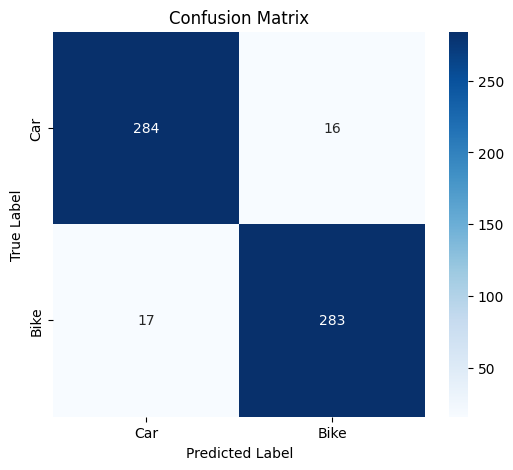

In [32]:
cm = confusion_matrix(test_label , y_pred_index)
print(cm)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[index_to_class[i] for i in range(len(index_to_class))],
    yticklabels=[index_to_class[i] for i in range(len(index_to_class))]
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Prediction Visualization Function

In [33]:
def show_random_predictions(test_images,test_labels,model,num_images=4,threshold=0.5):
    plt.figure(figsize=(15, 8))

    for i in range(num_images):
        idx = random.randint(0, len(test_images) - 1)
        img = test_images[idx]
        true_label_index = int(test_labels[idx])

        img_input = np.expand_dims(img, axis=0)
        prob_class_1 = model.predict(
            img_input,
            verbose=0
        )[0][0]

        pred_index = 1 if prob_class_1 >= threshold else 0

        pred_label = index_to_class[pred_index]
        true_label = index_to_class[true_label_index]

        confidence = (
            prob_class_1 if pred_index == 1
            else 1 - prob_class_1
        )

        result = (
            "Correct"
            if pred_index == true_label_index
            else "Wrong"
        )

        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.axis('off')

        plt.title(
            f"True: {true_label}\n"
            f"Predicted: {pred_label}\n"
            f"Confidence: {confidence:.2%}\n"
            f"{result}"
        )

    plt.tight_layout()
    plt.show()


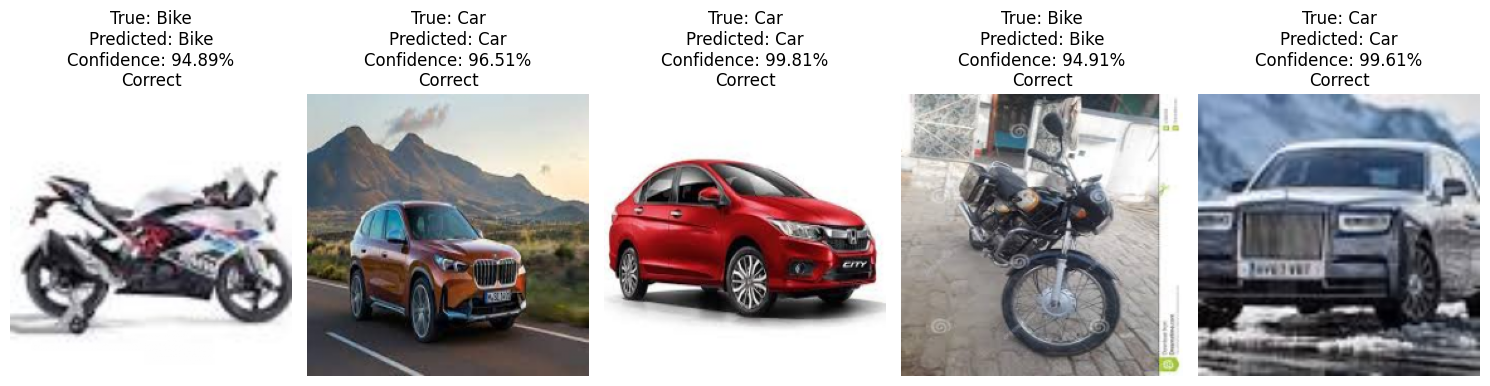

In [34]:
show_random_predictions(test_img , test_label , CNN , num_images=5)